# 从人类偏好到 PPO：可复现的小型 RLHF 实验

**运行方式：** 上传到 Google Colab → 选择 **T4 GPU** → 连接运行时后，在命令面板搜索 **Change runtime version**，选择 **2026.07 / 26.07（Python 3.12）** → 运行安装格 → **重启会话** → 从环境检查格继续。无需 API key，不使用付费 API，不上传模型或私人数据。

**不要使用 Python 3.13 运行本固定依赖版本。** 此 notebook 的 NumPy 1.26.4 需要 Python 3.9–3.12，本项目进一步限定为 Python 3.10–3.12。Colab 新会话可能恢复默认运行时，请每次确认 Python 版本。

实验路线：**公开人类偏好数据 → chosen 回答的 SFT → Bradley–Terry 奖励模型 → 带 KL 约束的 PPO + LoRA → 独立测试与导出**。

- 策略与奖励模型基座：`HuggingFaceTB/SmolLM2-135M-Instruct`，约 135M 参数。
- 数据：`Anthropic/hh-rlhf` 的 **helpful-base**，偏好标签来自数据集原有的人类比较；本实验不会新增人工标注。
- 这是使用现成预训练模型、公开数据和 TRL 的个人复现实验；不等同于独立实现 PPO、从零预训练模型，或生产规模 RLHF。
- 本 notebook 保留了一次完整运行的真实输出（`extended` 配置，Colab A100，2026-10-23）。该配置 PPO 峰值显存约 1.3 GiB，T4 同样可以运行。结果解读见 repo 的 README。

默认小实验用于验证完整流程。Colab 的显卡、网络和配额会影响时间；本 notebook 不承诺固定运行时长或质量提升。


## 1. 安装固定版本

使用 TRL 0.11.4 的经典 `PPOTrainer` 接口。先确认 Python 3.10–3.12；Colab 推荐选择 2026.07 的 Python 3.12 运行时。下面使用当前解释器安装并检查返回状态，安装失败会立即停止。

安装完成后，**必须选择「运行时 → 重启会话」（Restart session）**，然后从下一格继续。重启会话不会删除当前虚拟机已安装的包；不要选择「断开连接并删除运行时」。环境检查格会阻止在安装前的旧进程里继续导入 NumPy。


In [ ]:
import sys, os, json, subprocess, importlib.metadata as package_metadata
from pathlib import Path

def require_supported_python(version):
    if not ((3, 10) <= tuple(version[:2]) < (3, 13)):
        raise RuntimeError(
            f'当前 Python {version[0]}.{version[1]} 不适用于本 notebook。'
            '请先连接 Colab，在命令面板搜索 Change runtime version，'
            '选择 2026.07 / 26.07（Python 3.12）和 T4 GPU，再重新运行本格。'
        )

require_supported_python(sys.version_info)
PINS = {'numpy':'1.26.4', 'pandas':'2.2.3', 'transformers':'4.45.2',
        'tokenizers':'0.20.3', 'trl':'0.11.4', 'peft':'0.13.2',
        'accelerate':'1.10.1', 'datasets':'3.2.0', 'tyro':'0.8.14', 'rich':'13.9.4'}
SETUP_MARKER = Path('/tmp/rlhf_ppo_environment_v2.json') if Path('/content').exists() else Path.cwd()/'rlhf_ppo_environment_v2.json'

def installed_version(name):
    try: return package_metadata.version(name)
    except package_metadata.PackageNotFoundError: return None

previous = json.loads(SETUP_MARKER.read_text()) if SETUP_MARKER.exists() else {}
already_ready = (all(installed_version(k)==v for k,v in PINS.items())
                 and previous.get('pins')==PINS
                 and previous.get('python')==list(sys.version_info[:2])
                 and previous.get('install_pid') != os.getpid())
if already_ready:
    print('固定依赖已安装，当前会话已重启；可以继续下一格。')
else:
    # Reinstall the numeric wheels together to repair mixed/incomplete installations.
    subprocess.check_call([sys.executable,'-m','pip','install','--upgrade','--force-reinstall',
                           '--no-cache-dir','--only-binary=:all:',
                           'numpy==1.26.4','pandas==2.2.3'])
    subprocess.check_call([sys.executable,'-m','pip','install','--upgrade',
                           *[f'{k}=={v}' for k,v in PINS.items()], 'matplotlib>=3.8,<4'])
    # A clean subprocess checks on-disk packages rather than stale imports in this kernel.
    subprocess.check_call([sys.executable,'-c',
        'import numpy,pandas; from numpy.random import RandomState; '
        'from trl import PPOTrainer,PPOConfig,AutoModelForCausalLMWithValueHead; '
        'print("Fresh-process imports OK:",numpy.__version__,pandas.__version__)'])
    SETUP_MARKER.write_text(json.dumps(dict(pins=PINS,python=list(sys.version_info[:2]),
                                           install_pid=os.getpid())),encoding='utf-8')
    print('安装及独立进程检查通过。现在请选择「运行时 → 重启会话」，然后从下一格继续。')


安装及独立进程检查通过。现在请选择「运行时 → 重启会话」，然后从下一格继续。


In [ ]:
# This check runs before importing NumPy/pandas/training libraries.
import os, sys, json, importlib.metadata as package_metadata
from pathlib import Path
if not ((3,10) <= tuple(sys.version_info[:2]) < (3,13)):
    raise RuntimeError('请先切换到 Colab 2026.07 / 26.07（Python 3.12）运行时。')
SETUP_MARKER = Path('/tmp/rlhf_ppo_environment_v2.json') if Path('/content').exists() else Path.cwd()/'rlhf_ppo_environment_v2.json'
if not SETUP_MARKER.exists():
    raise RuntimeError('请先成功运行上一格安装步骤。')
setup = json.loads(SETUP_MARKER.read_text(encoding='utf-8'))
if setup['install_pid'] == os.getpid():
    raise RuntimeError('依赖已安装，但当前还是安装前的进程。请点击「运行时 → 重启会话」，再从本格继续。')
if setup['python'] != list(sys.version_info[:2]):
    raise RuntimeError('Python 版本发生变化，请重新运行安装格并重启会话。')
for name,expected in setup['pins'].items():
    actual = package_metadata.version(name)
    if actual != expected:
        raise RuntimeError(f'{name} 版本为 {actual}，预期 {expected}；请重新安装并重启。')
print('环境检查通过：',sys.version.split()[0],'NumPy',package_metadata.version('numpy'),
      'pandas',package_metadata.version('pandas'))


环境检查通过： 3.12.13 NumPy 1.26.4 pandas 2.2.3


In [ ]:
import os, json, math, time, random, hashlib, gc, copy, platform, shutil, warnings
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from datasets import load_dataset
from huggingface_hub import model_info, dataset_info
import transformers, trl, peft, accelerate, datasets
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
from peft import LoraConfig, TaskType, get_peft_model
from trl import PPOConfig, PPOTrainer, AutoModelForCausalLMWithValueHead
from IPython.display import display, Markdown

assert transformers.__version__ == '4.45.2', '请重启运行时后从本格重新开始。'
assert trl.__version__ == '0.11.4', '请重启运行时后从本格重新开始。'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', '请选择 Colab GPU 运行时；本完整实验不建议用 CPU。'
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))


GPU: NVIDIA A100-SXM4-40GB
VRAM GiB: 39.5


## 2. 实验规模与保存位置

先用 `PROFILE = "small"`。想检查更稳定的统计结果，可在一次全新运行中改成 `extended`；不要根据测试集表现反复选超参数。奖励模型、策略和价值头使用 fp32，135M 小模型配合 LoRA 以降低显存压力。

默认不挂载 Google Drive。Colab 断开会丢失本地文件，最后一节可以下载结果；需要长期保存时自行把运行目录复制到 Drive。


In [ ]:
PROFILE = 'extended'  # 'small' 或 'extended'
SETTINGS = {
    'small': dict(rm_train=512, rm_val=128, rm_test=128, sft_examples=256,
                  ppo_prompts=128, eval_prompts=24, rm_epochs=2, ppo_updates=16),
    'extended': dict(rm_train=4096, rm_val=512, rm_test=512, sft_examples=2048,
                     ppo_prompts=1024, eval_prompts=96, rm_epochs=3, ppo_updates=128),
}
CFG = dict(SETTINGS[PROFILE], seed=42, profile=PROFILE,
           model_id='HuggingFaceTB/SmolLM2-135M-Instruct', dataset_id='Anthropic/hh-rlhf',
           max_prompt_tokens=96, max_response_tokens=96, max_new_tokens=48,
           sft_batch=2, sft_grad_accum=4, sft_lr=1e-4,
           rm_pair_batch=2, rm_grad_accum=4, rm_lr=1e-4,
           ppo_batch=4, ppo_mini_batch=1, ppo_epochs=2, ppo_lr=1e-5,
           lora_r=8, lora_alpha=16, kl_coef=0.1)
RUN_NAME = time.strftime('rlhf_%Y%m%d_%H%M%S')
OUT = Path('/content') / RUN_NAME if Path('/content').exists() else Path.cwd() / RUN_NAME
OUT.mkdir(parents=True, exist_ok=False)
for name in ['metrics','data','checkpoints','samples','figures']:
    (OUT/name).mkdir()
WORK = OUT/'cache'  # full merged SFT base; excluded from the compact export
WORK.mkdir()
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
torch.cuda.manual_seed_all(CFG['seed'])
# Reproducibility is best effort: kernels and hardware can still produce differences.
MODEL_REV = model_info(CFG['model_id']).sha
DATA_REV = dataset_info(CFG['dataset_id']).sha
CFG.update(model_revision=MODEL_REV, dataset_revision=DATA_REV)
(OUT/'config.json').write_text(json.dumps(CFG, indent=2), encoding='utf-8')
versions = {x.__name__:x.__version__ for x in [torch,transformers,trl,peft,accelerate,datasets,np]}
versions.update(python=platform.python_version(), gpu=torch.cuda.get_device_name(0))
(OUT/'environment.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
print('Results:', OUT)
print(json.dumps(CFG, indent=2))


Results: /content/rlhf_20261023_080622
{
  "rm_train": 4096,
  "rm_val": 512,
  "rm_test": 512,
  "sft_examples": 2048,
  "ppo_prompts": 1024,
  "eval_prompts": 96,
  "rm_epochs": 3,
  "ppo_updates": 128,
  "seed": 42,
  "profile": "extended",
  "model_id": "HuggingFaceTB/SmolLM2-135M-Instruct",
  "dataset_id": "Anthropic/hh-rlhf",
  "max_prompt_tokens": 96,
  "max_response_tokens": 96,
  "max_new_tokens": 48,
  "sft_batch": 2,
  "sft_grad_accum": 4,
  "sft_lr": 0.0001,
  "rm_pair_batch": 2,
  "rm_grad_accum": 4,
  "rm_lr": 0.0001,
  "ppo_batch": 4,
  "ppo_mini_batch": 1,
  "ppo_epochs": 2,
  "ppo_lr": 1e-05,
  "lora_r": 8,
  "lora_alpha": 16,
  "kl_coef": 0.1,
  "model_revision": "12fd25f77366fa6b3b4b768ec3050bf629380bac",
  "dataset_revision": "09be8c5bbc57cb3887f3a9732ad6aa7ec602a1fa"
}


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


## 3. 读取人类偏好数据，按完整 prompt 去重

使用原始 `helpful-base/train` 和 `helpful-base/test`。从训练文件划分奖励模型训练、验证和 PPO prompt；测试文件只用于最终评估。SFT 使用奖励模型训练部分的 chosen 回答。**先按完整 prompt 划分，再截断**；截断后再次排除跨集合 prompt 碰撞。

数据集的历史对话可能含不准确或不当回答；`chosen` 只表示比较偏好，不代表事实真值。这里只下载公开数据，不使用你的课程或患者资料。


In [ ]:
import re
tokenizer = AutoTokenizer.from_pretrained(CFG['model_id'], revision=MODEL_REV)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'right'

def prompt_hash(text):
    return hashlib.sha256(text.strip().encode('utf-8')).hexdigest()

def parse_pair(row):
    marker = '\n\nAssistant:'
    if marker not in row['chosen'] or marker not in row['rejected']:
        return None
    cp, chosen = row['chosen'].rsplit(marker, 1)
    rp, rejected = row['rejected'].rsplit(marker, 1)
    if cp != rp or not chosen.strip() or not rejected.strip() or chosen.strip() == rejected.strip():
        return None
    parts = re.split(r'\n\n(Human|Assistant):', cp)
    messages = []
    for i in range(1, len(parts), 2):
        messages.append({'role':'user' if parts[i]=='Human' else 'assistant', 'content':parts[i+1].strip()})
    if not messages or messages[-1]['role'] != 'user':
        return None
    query = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=True)
    query = query[-CFG['max_prompt_tokens']:]
    def response_ids(text):
        return tokenizer.encode(text.strip(), add_special_tokens=False)[:CFG['max_response_tokens']-1] + [tokenizer.eos_token_id]
    cids, rids = response_ids(chosen), response_ids(rejected)
    if cids == rids:  # do not train contradictory labels after truncation
        return None
    return dict(prompt_hash=prompt_hash(cp), query_ids=query, chosen_ids=cids, rejected_ids=rids,
                chosen_text=chosen.strip(), rejected_text=rejected.strip(), messages=messages)

def collect_unique(stream, count, excluded=None):
    excluded = set() if excluded is None else set(excluded)
    result, seen_full, seen_tokens = [], set(), set()
    for raw in stream:
        ex = parse_pair(raw)
        if ex is None: continue
        token_key = tuple(ex['query_ids'])
        if ex['prompt_hash'] in excluded or ex['prompt_hash'] in seen_full or token_key in seen_tokens:
            continue
        seen_full.add(ex['prompt_hash']); seen_tokens.add(token_key); result.append(ex)
        if len(result) == count: break
    if len(result) != count:
        raise RuntimeError(f'Only found {len(result)} distinct usable prompts; need {count}.')
    return result

train_stream = load_dataset(CFG['dataset_id'], data_dir='helpful-base', split='train',
                            revision=DATA_REV, streaming=True).shuffle(seed=CFG['seed'], buffer_size=5000)
needed = CFG['rm_train'] + CFG['rm_val'] + CFG['ppo_prompts']
all_train = collect_unique(train_stream, needed)
rm_train = all_train[:CFG['rm_train']]
rm_val = all_train[CFG['rm_train']:CFG['rm_train']+CFG['rm_val']]
ppo_data = all_train[-CFG['ppo_prompts']:]
assert CFG['sft_examples'] <= len(rm_train)
sft_data = rm_train[:CFG['sft_examples']]
test_stream = load_dataset(CFG['dataset_id'], data_dir='helpful-base', split='test',
                           revision=DATA_REV, streaming=True).shuffle(seed=CFG['seed']+1, buffer_size=2000)
train_hashes = {ex['prompt_hash'] for ex in all_train}
test_candidates = collect_unique(test_stream, CFG['rm_test']*2, train_hashes)
train_token_keys = {tuple(ex['query_ids']) for ex in all_train}
rm_test = [ex for ex in test_candidates if tuple(ex['query_ids']) not in train_token_keys][:CFG['rm_test']]
assert len(rm_test) == CFG['rm_test'], 'Increase test_candidates if truncation removed too many prompts.'
eval_data = rm_test[:CFG['eval_prompts']]

groups = {'rm_train':rm_train, 'rm_val':rm_val, 'ppo':ppo_data, 'rm_test':rm_test}
for a,ga in groups.items():
    for b,gb in groups.items():
        if a < b:
            assert not ({x['prompt_hash'] for x in ga} & {x['prompt_hash'] for x in gb})
            assert not ({tuple(x['query_ids']) for x in ga} & {tuple(x['query_ids']) for x in gb})
for name,rows in groups.items():
    with (OUT/'data'/f'{name}.jsonl').open('w',encoding='utf-8') as f:
        for row in rows: f.write(json.dumps(row,ensure_ascii=False)+'\n')
print({k:len(v) for k,v in groups.items()}, 'sft:',len(sft_data))


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

{'rm_train': 4096, 'rm_val': 512, 'ppo': 1024, 'rm_test': 512} sft: 2048


In [ ]:
def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')

def lora_config(task_type):
    return LoraConfig(task_type=task_type, r=CFG['lora_r'], lora_alpha=CFG['lora_alpha'],
                      lora_dropout=0.0, bias='none', target_modules=['q_proj','v_proj'])

def pad_sequences(sequences, labels=None, left=False):
    # left=True is used for the reward model: the last position is then always a real token.
    n = max(len(x) for x in sequences)
    ids = torch.full((len(sequences),n), tokenizer.pad_token_id, dtype=torch.long)
    mask = torch.zeros_like(ids)
    labs = torch.full_like(ids, -100) if labels is not None else None
    for i, seq in enumerate(sequences):
        sl = slice(n-len(seq), n) if left else slice(0, len(seq))
        ids[i,sl] = torch.tensor(seq)
        mask[i,sl] = 1
        if labs is not None: labs[i,sl] = torch.tensor(labels[i])
    batch={'input_ids':ids.to(DEVICE), 'attention_mask':mask.to(DEVICE)}
    if left:
        batch['position_ids'] = (mask.cumsum(-1)-1).clamp(min=0).to(DEVICE)
    if labs is not None: batch['labels']=labs.to(DEVICE)
    return batch

# SmolLM2 uses <|im_end|> as both eos and pad, and the chat template puts <|im_end|> inside every prompt.
# transformers 4.45 pools a sequence-classification score at the token before the FIRST pad id, which would
# be inside the prompt, so the reward model would never see the response. We left-pad reward-model inputs and
# set the model's pad id to -1 (never present), so HF pools the last position, which is the real last token.
RM_POOL_PAD_ID = -1

def sft_batch(rows):
    seqs=[x['query_ids']+x['chosen_ids'] for x in rows]
    labels=[[-100]*len(x['query_ids'])+x['chosen_ids'] for x in rows]
    return pad_sequences(seqs, labels)

def pair_batch(rows):
    # Ordered as [all chosen, all rejected] so each difference matches one human comparison.
    seqs=[x['query_ids']+x['chosen_ids'] for x in rows] + [x['query_ids']+x['rejected_ids'] for x in rows]
    return pad_sequences(seqs, left=True)

@torch.no_grad()
def check_reward_sees_response(model):
    # chosen and rejected share the prompt; if the scores are identical the model is not reading the response.
    model.eval()
    s=model(**pair_batch(rm_val[:4])).logits.squeeze(-1).float()
    gap=(s[:4]-s[4:]).abs()
    assert (gap>1e-6).all(), f'Reward scores identical for chosen/rejected: {gap.tolist()}'
    print('Reward model reads the response. |chosen-rejected| =', [round(x,5) for x in gap.tolist()])

def pair_loss(scores, n):
    margin=scores[:n].float()-scores[n:].float()
    return F.softplus(-margin).mean() + 0.001*scores.float().square().mean()

def wilson_interval(correct,total):
    z=1.96; p=correct/total; den=1+z*z/total
    center=(p+z*z/(2*total))/den
    half=z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/den
    return [center-half,center+half]

@torch.no_grad()
def evaluate_reward(model, rows):
    model.eval(); margins=[]; scores=[]; losses=[]
    for i in range(0,len(rows),CFG['rm_pair_batch']):
        chunk=rows[i:i+CFG['rm_pair_batch']]
        s=model(**pair_batch(chunk)).logits.squeeze(-1).float()
        margins.extend((s[:len(chunk)]-s[len(chunk):]).cpu().tolist())
        scores.extend(s.cpu().tolist())
        losses.extend(F.softplus(-(s[:len(chunk)]-s[len(chunk):])).cpu().tolist())
    margins=np.asarray(margins); correct=int((margins>0).sum())
    return dict(pair_accuracy=correct/len(rows), accuracy_95ci=wilson_interval(correct,len(rows)),
                pairs=len(rows), pair_loss=float(np.mean(losses)), mean_margin=float(margins.mean()),
                score_mean=float(np.mean(scores)), score_std=float(np.std(scores)))

def finite_gradients(model):
    return all(torch.isfinite(p.grad).all().item() for p in model.parameters() if p.grad is not None)


## 4. 在 chosen 回答上做一次 SFT

模型已有 instruct 权重；这里额外做一轮小规模领域适配。loss 只作用于 assistant 回答，prompt 和 padding 均掩码为 `-100`。记录真实训练 loss，保存 SFT LoRA，并把合并后的权重作为 PPO 的固定参考基座。


In [ ]:
sft_model = AutoModelForCausalLM.from_pretrained(CFG['model_id'], revision=MODEL_REV,
                                               torch_dtype=torch.float32, attn_implementation='eager').to(DEVICE)
sft_model = get_peft_model(sft_model,lora_config(TaskType.CAUSAL_LM))
sft_model.config.use_cache=False
sft_model.print_trainable_parameters()
optimizer=torch.optim.AdamW([p for p in sft_model.parameters() if p.requires_grad],lr=CFG['sft_lr'])
loader=DataLoader(sft_data,batch_size=CFG['sft_batch'],shuffle=True,collate_fn=lambda x:x,
                  generator=torch.Generator().manual_seed(CFG['seed']))
sft_logs=[]; optimizer.zero_grad(); sft_model.train(); start=time.time()
for step,rows in enumerate(loader):
    loss=sft_model(**sft_batch(rows)).loss
    if not torch.isfinite(loss): raise RuntimeError('Nonfinite SFT loss')
    # Correctly normalize the final, possibly shorter accumulation group.
    group_start=(step//CFG['sft_grad_accum'])*CFG['sft_grad_accum']
    group_size=min(CFG['sft_grad_accum'],len(loader)-group_start)
    (loss/group_size).backward()
    if (step+1)%CFG['sft_grad_accum']==0 or step+1==len(loader):
        assert finite_gradients(sft_model)
        torch.nn.utils.clip_grad_norm_(sft_model.parameters(),1.0)
        optimizer.step(); optimizer.zero_grad()
    sft_logs.append({'microstep':step+1,'loss':float(loss.detach()),'seconds':time.time()-start})
    if (step+1)%20==0: print('SFT',step+1,'/',len(loader),'loss',round(sft_logs[-1]['loss'],4))
pd.DataFrame(sft_logs).to_csv(OUT/'metrics/sft.csv',index=False)
sft_model.save_pretrained(OUT/'checkpoints/sft_adapter',safe_serialization=True)
tokenizer.save_pretrained(OUT/'checkpoints/sft_adapter')
sft_model = sft_model.merge_and_unload()
sft_model.config.use_cache=True
sft_model.save_pretrained(WORK/'sft_merged',safe_serialization=True)
tokenizer.save_pretrained(WORK/'sft_merged')
del sft_model,optimizer,loader,loss
gc.collect(); torch.cuda.empty_cache()
print('SFT complete; adapter and merged reference saved.')


config.json:   0%|          | 0.00/861 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/269M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

trainable params: 460,800 || all params: 134,975,808 || trainable%: 0.3414
SFT 20 / 1024 loss 2.2816
SFT 40 / 1024 loss 3.1251
SFT 60 / 1024 loss 2.3993
SFT 80 / 1024 loss 2.1756
SFT 100 / 1024 loss 2.8385
SFT 120 / 1024 loss 2.4607
SFT 140 / 1024 loss 2.1824
SFT 160 / 1024 loss 2.0843
SFT 180 / 1024 loss 2.6087
SFT 200 / 1024 loss 2.345
SFT 220 / 1024 loss 2.3637
SFT 240 / 1024 loss 1.7381
SFT 260 / 1024 loss 2.1373
SFT 280 / 1024 loss 2.3828
SFT 300 / 1024 loss 1.8573
SFT 320 / 1024 loss 2.3812
SFT 340 / 1024 loss 2.3176
SFT 360 / 1024 loss 2.3259
SFT 380 / 1024 loss 1.9302
SFT 400 / 1024 loss 2.1964
SFT 420 / 1024 loss 2.3863
SFT 440 / 1024 loss 1.8876
SFT 460 / 1024 loss 2.4916
SFT 480 / 1024 loss 1.0064
SFT 500 / 1024 loss 2.4237
SFT 520 / 1024 loss 2.1187
SFT 540 / 1024 loss 1.8654
SFT 560 / 1024 loss 2.1875
SFT 580 / 1024 loss 2.3626
SFT 600 / 1024 loss 2.4268
SFT 620 / 1024 loss 1.8174
SFT 640 / 1024 loss 2.5231
SFT 660 / 1024 loss 1.8906
SFT 680 / 1024 loss 1.5288
SFT 700 / 10

## 5. 训练独立奖励模型（人类偏好标签）

奖励模型由同一 **原始 instruct 基座**另行初始化，使用独立 LoRA 和 scalar score head。目标是降低 `softplus(-(r_chosen - r_rejected))`，附加小的分数正则。

每轮只看验证集选择 checkpoint；测试集暂不使用。比较一个随机初始化 score head 的基线，避免把训练前已经存在的信号误称为训练收益。


In [ ]:
reward_model = AutoModelForSequenceClassification.from_pretrained(
    CFG['model_id'],revision=MODEL_REV,num_labels=1,torch_dtype=torch.float32,
    attn_implementation='eager').to(DEVICE)
reward_model.config.pad_token_id=RM_POOL_PAD_ID
reward_model.config.use_cache=False
reward_model=get_peft_model(reward_model,lora_config(TaskType.SEQ_CLS))
reward_model.print_trainable_parameters()
assert any('score' in n and p.requires_grad for n,p in reward_model.named_parameters()), 'Reward head must train.'
check_reward_sees_response(reward_model)
rm_initial_val=evaluate_reward(reward_model,rm_val)
optimizer=torch.optim.AdamW([p for p in reward_model.parameters() if p.requires_grad],lr=CFG['rm_lr'])
rm_logs=[]; val_logs=[]; best_loss=float('inf'); start=time.time()
for epoch in range(CFG['rm_epochs']):
    loader=DataLoader(rm_train,batch_size=CFG['rm_pair_batch'],shuffle=True,collate_fn=lambda x:x,
                      generator=torch.Generator().manual_seed(CFG['seed']+epoch))
    reward_model.train(); optimizer.zero_grad()
    for step,rows in enumerate(loader):
        scores=reward_model(**pair_batch(rows)).logits.squeeze(-1)
        loss=pair_loss(scores,len(rows))
        if not torch.isfinite(loss): raise RuntimeError('Nonfinite reward loss')
        group_start=(step//CFG['rm_grad_accum'])*CFG['rm_grad_accum']
        group_size=min(CFG['rm_grad_accum'],len(loader)-group_start)
        (loss/group_size).backward()
        if (step+1)%CFG['rm_grad_accum']==0 or step+1==len(loader):
            assert finite_gradients(reward_model)
            torch.nn.utils.clip_grad_norm_(reward_model.parameters(),1.0)
            optimizer.step(); optimizer.zero_grad()
        rm_logs.append({'epoch':epoch+1,'microstep':step+1,'loss':float(loss.detach()),'seconds':time.time()-start})
        if (step+1)%50==0: print('RM epoch',epoch+1,'step',step+1,'loss',round(rm_logs[-1]['loss'],4))
    val=evaluate_reward(reward_model,rm_val); val_logs.append(dict(epoch=epoch+1,**val))
    print('Reward validation:',val)
    if val['pair_loss']<best_loss:
        best_loss=val['pair_loss']
        reward_model.save_pretrained(OUT/'checkpoints/reward_adapter',safe_serialization=True)
        save_json(OUT/'metrics/reward_best_validation.json',dict(epoch=epoch+1,**val))
pd.DataFrame(rm_logs).to_csv(OUT/'metrics/reward_training.csv',index=False)
save_json(OUT/'metrics/reward_validation_history.json',val_logs)
save_json(OUT/'metrics/reward_initial_validation.json',rm_initial_val)
del optimizer,loader,scores,loss
from peft import PeftModel
del reward_model
gc.collect(); torch.cuda.empty_cache()
reward_base = AutoModelForSequenceClassification.from_pretrained(
    CFG['model_id'],revision=MODEL_REV,num_labels=1,torch_dtype=torch.float32,
    attn_implementation='eager').to(DEVICE)
reward_base.config.pad_token_id=RM_POOL_PAD_ID
reward_model=PeftModel.from_pretrained(reward_base,str(OUT/'checkpoints/reward_adapter'),is_trainable=False)
del reward_base
reward_model.eval()
for p in reward_model.parameters(): p.requires_grad=False
check_reward_sees_response(reward_model)
rm_best_val=evaluate_reward(reward_model,rm_val)
# Fixed normalization from validation, never updated using the test set or PPO rollouts.
REWARD_MEAN=rm_best_val['score_mean']; REWARD_STD=max(rm_best_val['score_std'],0.1)
save_json(OUT/'metrics/reward_normalization.json',dict(mean=REWARD_MEAN,std=REWARD_STD,clip=5.0))
gc.collect(); torch.cuda.empty_cache()


Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at HuggingFaceTB/SmolLM2-135M-Instruct and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 461,376 || all params: 134,976,960 || trainable%: 0.3418
Reward model reads the response. |chosen-rejected| = [0.26356, 0.15804, 0.01626, 0.24479]
RM epoch 1 step 50 loss 0.6257
RM epoch 1 step 100 loss 0.5573
RM epoch 1 step 150 loss 0.6326
RM epoch 1 step 200 loss 0.6598
RM epoch 1 step 250 loss 0.4021
RM epoch 1 step 300 loss 0.638
RM epoch 1 step 350 loss 0.8486
RM epoch 1 step 400 loss 0.7095
RM epoch 1 step 450 loss 0.4401
RM epoch 1 step 500 loss 0.4636
RM epoch 1 step 550 loss 1.0321
RM epoch 1 step 600 loss 0.5808
RM epoch 1 step 650 loss 0.8311
RM epoch 1 step 700 loss 0.4595
RM epoch 1 step 750 loss 1.1029
RM epoch 1 step 800 loss 0.9241
RM epoch 1 step 850 loss 0.6808
RM epoch 1 step 900 loss 0.6354
RM epoch 1 step 950 loss 0.5235
RM epoch 1 step 1000 loss 1.0178
RM epoch 1 step 1050 loss 0.7925
RM epoch 1 step 1100 loss 0.9517
RM epoch 1 step 1150 loss 0.7443
RM epoch 1 step 1200 loss 0.6583
RM epoch 1 step 1250 loss 0.8581
RM epoch 1 step 1300 loss 0.941

Some weights of LlamaForSequenceClassification were not initialized from the model checkpoint at HuggingFaceTB/SmolLM2-135M-Instruct and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Reward model reads the response. |chosen-rejected| = [0.23273, 0.78394, 0.16782, 0.8301]


## 6. PPO 策略与评估函数

PPO 在合并后的 SFT 基座上训练**新的** LoRA 和 value head。TRL 在计算参考分布时关闭这个新的 LoRA，因此参考策略固定为 SFT 权重，不会随着 PPO 更新。

评估使用固定测试 prompt。生成过程每个 prompt 使用相同 seed；奖励由固定奖励模型给出。额外记录生成长度和策略相对于参考模型的 sampled log-ratio。**同一个奖励模型的分数提高，只是代理指标，不证明人类更喜欢回答。**


In [ ]:
policy = AutoModelForCausalLMWithValueHead.from_pretrained(
    str(WORK/'sft_merged'),peft_config=lora_config(TaskType.CAUSAL_LM),
    torch_dtype=torch.float32,attn_implementation='eager',summary_dropout_prob=0.0).to(DEVICE)
assert policy.is_peft_model
policy.pretrained_model.config.use_cache=True
tokenizer.padding_side='left'
ppo_config=PPOConfig(model_name=CFG['model_id'],seed=CFG['seed'],
    batch_size=CFG['ppo_batch'],mini_batch_size=CFG['ppo_mini_batch'],
    gradient_accumulation_steps=1,ppo_epochs=CFG['ppo_epochs'],learning_rate=CFG['ppo_lr'],
    adap_kl_ctrl=False,init_kl_coef=CFG['kl_coef'],kl_penalty='kl',
    log_with=None,early_stopping=True,target_kl=0.1,max_grad_norm=1.0,
    use_score_scaling=False,use_score_norm=False)
ppo_trainer=PPOTrainer(config=ppo_config,model=policy,ref_model=None,tokenizer=tokenizer)
# Temperature=1 and no top-k/top-p filtering keep rollout and training distributions aligned.
GEN_KW=dict(max_new_tokens=CFG['max_new_tokens'],min_new_tokens=1,
            do_sample=True,temperature=1.0,top_k=0,top_p=1.0,
            pad_token_id=tokenizer.pad_token_id,eos_token_id=tokenizer.eos_token_id)

@torch.no_grad()
def score_responses(queries,responses,normalized=False):
    # Keep all generated response tokens; max_new_tokens <= max_response_tokens.
    sequences=[q.detach().cpu().tolist()+r.detach().cpu().tolist() for q,r in zip(queries,responses)]
    raw=reward_model(**pad_sequences(sequences, left=True)).logits.squeeze(-1).float()
    if normalized: return ((raw-REWARD_MEAN)/REWARD_STD).clamp(-5,5)
    return raw

@torch.no_grad()
def response_logprobs(q,r,reference=False):
    seq=torch.cat([q,r]).unsqueeze(0).to(DEVICE)
    with policy.pretrained_model.disable_adapter() if reference else nullcontext():
        logits=policy.pretrained_model(input_ids=seq,attention_mask=torch.ones_like(seq)).logits
    lp=F.log_softmax(logits[:,:-1].float(),dim=-1).gather(-1,seq[:,1:].unsqueeze(-1)).squeeze(-1)
    return lp[0,len(q)-1:].detach().cpu()

@torch.no_grad()
def evaluate_policy(stage):
    policy.eval(); rows=[]
    for i,ex in enumerate(eval_data):
        torch.manual_seed(CFG['seed']+10000+i); torch.cuda.manual_seed_all(CFG['seed']+10000+i)
        q=torch.tensor(ex['query_ids'],device=DEVICE,dtype=torch.long)
        r=ppo_trainer.generate(q,return_prompt=False,attention_mask=torch.ones_like(q).unsqueeze(0),**GEN_KW).squeeze(0)
        score=float(score_responses([q],[r])[0])
        sample_log_ratio=float((response_logprobs(q,r)-response_logprobs(q,r,reference=True)).mean())
        rows.append(dict(stage=stage,prompt_hash=ex['prompt_hash'],
                         prompt=tokenizer.decode(q,skip_special_tokens=True),
                         response=tokenizer.decode(r,skip_special_tokens=True),
                         reward=score,response_tokens=len(r),sampled_log_ratio_per_token=sample_log_ratio))
        if (i+1)%8==0: print(stage,'evaluation',i+1,'/',len(eval_data))
    pd.DataFrame(rows).to_json(OUT/'samples'/f'{stage}.jsonl',orient='records',lines=True,force_ascii=False)
    return rows


/usr/local/lib/python3.12/dist-packages/trl/trainer/ppo_config.py:207: FutureWarning: `PPOConfig` is deprecated and will be removed in the future. Please use `PPOv2Config` with `PPOv2Trainer` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/trl/trainer/ppo_trainer.py:193: FutureWarning: `PPOTrainer` is deprecated and will be removed in trl v0.12. Please use `PPOv2Trainer` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/trl/trainer/ppo_trainer.py:273: UserWarning: No dataset is provided. Make sure to set config.batch_size to the correct value before training.
  warnings.warn(


In [ ]:
before_rows=evaluate_policy('sft_before_ppo')
print('Baseline mean reward:',np.mean([r['reward'] for r in before_rows]))


Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)


sft_before_ppo evaluation 8 / 96
sft_before_ppo evaluation 16 / 96
sft_before_ppo evaluation 24 / 96
sft_before_ppo evaluation 32 / 96
sft_before_ppo evaluation 40 / 96
sft_before_ppo evaluation 48 / 96
sft_before_ppo evaluation 56 / 96
sft_before_ppo evaluation 64 / 96
sft_before_ppo evaluation 72 / 96
sft_before_ppo evaluation 80 / 96
sft_before_ppo evaluation 88 / 96
sft_before_ppo evaluation 96 / 96
Baseline mean reward: -0.14664730398605266


## 7. 运行 PPO

每次采样 4 个训练 prompt → 生成回答 → 冻结奖励模型打分 → TRL PPO 更新 LoRA 和 value head。记录 reward、KL、策略损失、价值损失、生成长度和显存峰值。

这是短训练，可能出现奖励过拟合、输出变长、训练不稳定或无提升。不要只挑选好看的回答报告结果。


In [ ]:
ppo_logs=[]; rollout_samples=[]; start=time.time()
rng=random.Random(CFG['seed']+77)
torch.cuda.reset_peak_memory_stats()
for update in range(CFG['ppo_updates']):
    batch=rng.sample(ppo_data,CFG['ppo_batch'])
    queries=[torch.tensor(ex['query_ids'],dtype=torch.long,device=DEVICE) for ex in batch]
    policy.eval()
    with torch.no_grad():
        responses=[ppo_trainer.generate(q,return_prompt=False,attention_mask=torch.ones_like(q).unsqueeze(0),**GEN_KW).squeeze(0) for q in queries]
        raw_scores=score_responses(queries,responses)
        train_scores=((raw_scores-REWARD_MEAN)/REWARD_STD).clamp(-5,5)
    assert torch.isfinite(train_scores).all()
    policy.train()
    stats=ppo_trainer.step(queries,responses,[s.detach() for s in train_scores])
    row=dict(update=update+1,raw_reward=float(raw_scores.mean()),
             normalized_reward=float(train_scores.mean()),mean_response_tokens=float(np.mean([len(r) for r in responses])),
             peak_vram_gib=torch.cuda.max_memory_allocated()/2**30,seconds=time.time()-start)
    for key in ['objective/kl','ppo/loss/policy','ppo/loss/value','ppo/policy/approxkl','ppo/policy/clipfrac']:
        if key in stats: row[key]=float(np.asarray(stats[key]).mean())
    if not all(np.isfinite(v) for v in row.values()): raise RuntimeError(f'Nonfinite PPO metrics: {row}')
    ppo_logs.append(row)
    for ex,r,score in zip(batch,responses,raw_scores):
        rollout_samples.append(dict(update=update+1,prompt_hash=ex['prompt_hash'],
                                   response=tokenizer.decode(r,skip_special_tokens=True),reward=float(score)))
    pd.DataFrame(ppo_logs).to_csv(OUT/'metrics/ppo.csv',index=False)
    print('PPO',update+1,'/',CFG['ppo_updates'],'reward',round(row['raw_reward'],3),
          'KL',round(row.get('objective/kl',float('nan')),4),'VRAM',round(row['peak_vram_gib'],2),'GiB')
(OUT/'checkpoints/ppo_adapter').mkdir(parents=True,exist_ok=True)
policy.save_pretrained(OUT/'checkpoints/ppo_adapter')
tokenizer.save_pretrained(OUT/'checkpoints/ppo_adapter')
pd.DataFrame(rollout_samples).to_json(OUT/'samples/ppo_rollouts.jsonl',orient='records',lines=True,force_ascii=False)


PPO 1 / 128 reward -0.447 KL 0.0 VRAM 1.3 GiB
PPO 2 / 128 reward 0.25 KL 0.0005 VRAM 1.3 GiB
PPO 3 / 128 reward -0.097 KL 0.0029 VRAM 1.3 GiB
PPO 4 / 128 reward -0.878 KL -0.0026 VRAM 1.3 GiB
PPO 5 / 128 reward -0.401 KL 0.0167 VRAM 1.3 GiB
PPO 6 / 128 reward 0.503 KL -0.006 VRAM 1.3 GiB
PPO 7 / 128 reward 0.013 KL -0.0067 VRAM 1.3 GiB
PPO 8 / 128 reward -0.401 KL 0.0027 VRAM 1.3 GiB
PPO 9 / 128 reward -0.267 KL -0.0129 VRAM 1.3 GiB
PPO 10 / 128 reward -0.785 KL 0.003 VRAM 1.3 GiB
PPO 11 / 128 reward -0.092 KL 0.0078 VRAM 1.3 GiB
PPO 12 / 128 reward 0.164 KL -0.0067 VRAM 1.3 GiB
PPO 13 / 128 reward 0.254 KL -0.018 VRAM 1.3 GiB
PPO 14 / 128 reward 0.489 KL -0.0216 VRAM 1.3 GiB
PPO 15 / 128 reward 0.231 KL 0.0019 VRAM 1.3 GiB
PPO 16 / 128 reward -0.135 KL 0.0133 VRAM 1.3 GiB
PPO 17 / 128 reward -0.649 KL 0.009 VRAM 1.3 GiB
PPO 18 / 128 reward 0.292 KL 0.0146 VRAM 1.3 GiB
PPO 19 / 128 reward -0.751 KL 0.0088 VRAM 1.3 GiB
PPO 20 / 128 reward -0.167 KL -0.0254 VRAM 1.3 GiB
PPO 21 / 128 rewa

## 8. 一次性测试与前后对比

奖励模型的独立测试准确率衡量它能否区分原始人类偏好对。SFT/PPO 对比在相同测试 prompt 上进行，bootstrap 区间按 prompt 重采样。

**本格之后不要根据测试结果继续调参再宣称独立测试**。下一次调参应另留新的测试集，或明确报告探索性实验。生成质量还需要盲评，最后会输出一个人工评价表。


In [ ]:
reward_test=evaluate_reward(reward_model,rm_test)
after_rows=evaluate_policy('ppo_after')
before_df=pd.DataFrame(before_rows); after_df=pd.DataFrame(after_rows)
comparison=before_df.merge(after_df,on='prompt_hash',suffixes=('_before','_after'),validate='one_to_one')
delta=(comparison.reward_after-comparison.reward_before).to_numpy()
boot_rng=np.random.default_rng(CFG['seed']+999)
boot=np.asarray([boot_rng.choice(delta,len(delta),replace=True).mean() for _ in range(2000)])
summary=dict(
    status='completed',experiment='public-human-preference RLHF reproduction',config=CFG,
    reward_initial_validation=rm_initial_val,reward_best_validation=rm_best_val,reward_test=reward_test,
    ppo_updates_completed=len(ppo_logs),ppo_rollouts_completed=len(rollout_samples),
    eval_prompts=len(delta),before_mean_reward=float(comparison.reward_before.mean()),
    after_mean_reward=float(comparison.reward_after.mean()),mean_reward_delta=float(delta.mean()),
    reward_delta_bootstrap_95ci=np.quantile(boot,[0.025,0.975]).tolist(),
    proxy_reward_win_rate=float((delta>0).mean()),
    before_mean_response_tokens=float(comparison.response_tokens_before.mean()),
    after_mean_response_tokens=float(comparison.response_tokens_after.mean()),
    after_sampled_log_ratio_per_token=float(comparison.sampled_log_ratio_per_token_after.mean()),
    peak_ppo_vram_gib=max(x['peak_vram_gib'] for x in ppo_logs),
    quality_claim='No independent human quality improvement established; reward is a learned proxy.')
save_json(OUT/'metrics/summary.json',summary)
comparison.to_csv(OUT/'samples/before_after.csv',index=False)
display(pd.DataFrame([dict(stage='SFT',reward=summary['before_mean_reward'],tokens=summary['before_mean_response_tokens']),
                      dict(stage='PPO',reward=summary['after_mean_reward'],tokens=summary['after_mean_response_tokens'])]))
print('Reward model test:',reward_test)
print('Reward delta 95% CI:',summary['reward_delta_bootstrap_95ci'])
if reward_test['pair_accuracy'] <= 0.5:
    warnings.warn('奖励模型测试准确率没有超过随机基线；PPO 分数不能作为偏好改善证据。')
elif reward_test['accuracy_95ci'][0] <= 0.5:
    warnings.warn('奖励模型准确率区间仍包含 50%；样本太少或信号较弱。')
display(comparison[['prompt_before','response_before','response_after','reward_before','reward_after']].head(5))


ppo_after evaluation 8 / 96
ppo_after evaluation 16 / 96
ppo_after evaluation 24 / 96
ppo_after evaluation 32 / 96
ppo_after evaluation 40 / 96
ppo_after evaluation 48 / 96
ppo_after evaluation 56 / 96
ppo_after evaluation 64 / 96
ppo_after evaluation 72 / 96
ppo_after evaluation 80 / 96
ppo_after evaluation 88 / 96
ppo_after evaluation 96 / 96


  stage    reward     tokens
0   SFT -0.146647  30.177083
1   PPO -0.143897  31.625000

Reward model test: {'pair_accuracy': 0.6953125, 'accuracy_95ci': [0.6541107886647157, 0.7336051303305728], 'pairs': 512, 'pair_loss': 0.5879364396387246, 'mean_margin': 0.496375588234514, 'score_mean': -0.06806821480859071, 'score_std': 0.9978012491484698}
Reward delta 95% CI: [-0.15876844300267595, 0.161782104258115]


                                       prompt_before  \
0   thought it had a number inside. I remember my...   
1   and natural that it’s almost irresistible.  W...   
2   the best superhero movies?\nassistant\nThe fi...   
3   ingredients, which may be stir-fried, deep-fr...   
4  20th century, mail delivery was organized alon...   

                                     response_before  \
0  They were always forever famous, or got into y...   
1  Some artists might be thinking about other mus...   
2  I didn’t have any preferences for what titles?...   
3  Cow’s Fries and British Bake Off are two of th...   
4  It's comical, in retrospect, to see the works ...   

                                      response_after  reward_before  \
0  They were always forever famous, or got into y...      -1.411082   
1  Some artists might be thinking about other mus...       2.368427   
2  I didn’t have any preferences for what titles?...       1.999883   
3  Cow’s Fries and British Bake Off are tw

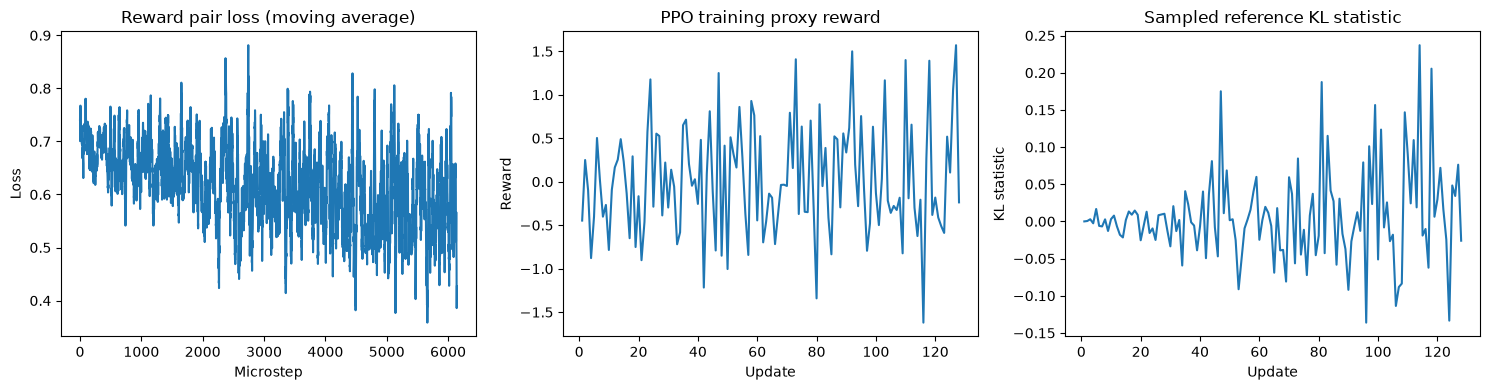

人工评价时把 blinded 表给评价者；不要同时给答案对应表。


In [ ]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(pd.DataFrame(rm_logs)['loss'].rolling(20,min_periods=1).mean())
axes[0].set(title='Reward pair loss (moving average)',xlabel='Microstep',ylabel='Loss')
axes[1].plot([x['update'] for x in ppo_logs],[x['raw_reward'] for x in ppo_logs])
axes[1].set(title='PPO training proxy reward',xlabel='Update',ylabel='Reward')
axes[2].plot([x['update'] for x in ppo_logs],[x.get('objective/kl',np.nan) for x in ppo_logs])
axes[2].set(title='Sampled reference KL statistic',xlabel='Update',ylabel='KL statistic')
fig.tight_layout(); fig.savefig(OUT/'figures/training.png',dpi=160); plt.show()

# Blind A/B order; leave labels blank for a real reviewer. Do not auto-fill human judgments.
blind=[]; key=[]; rng=random.Random(CFG['seed']+101)
for i,row in comparison.iterrows():
    flip=rng.choice([False,True])
    blind.append(dict(id=i,prompt=row.prompt_before,
                      answer_A=row.response_after if flip else row.response_before,
                      answer_B=row.response_before if flip else row.response_after,
                      preference='',reason=''))
    key.append(dict(id=i,A='PPO' if flip else 'SFT',B='SFT' if flip else 'PPO'))
pd.DataFrame(blind).to_csv(OUT/'samples/human_review_blinded.csv',index=False)
pd.DataFrame(key).to_csv(OUT/'samples/human_review_key_keep_separate.csv',index=False)
print('人工评价时把 blinded 表给评价者；不要同时给答案对应表。')


## 9. 导出可核验记录与保守的简历表述

导出包含配置、版本、数据子集、三个 LoRA checkpoint、日志、图表、生成样本和未填写的人工盲评表。为控制体积，不打包合并后的完整 SFT 基座；可以用原始模型 + SFT adapter 重新构建，再加载 PPO adapter。不要把未完成的人类评价或未观察到的提升写进简历。


In [ ]:
resume_text=(
    f'Completed a small-scale RLHF reproduction using a 135M-parameter language model and public human preference data; '
    f'adapted the policy with SFT, trained a Bradley-Terry reward model on {len(rm_train):,} preference pairs, '
    f'and ran {len(ppo_logs)} PPO updates with LoRA and a fixed SFT reference. '
    f'Evaluated reward-model ranking on {len(rm_test)} held-out pairs and compared generated responses on '
    f'{len(eval_data)} held-out prompts while tracking reward, KL statistics, response length, and GPU memory.'
)
(OUT/'resume_after_run.txt').write_text(resume_text,encoding='utf-8')
report=f"""# Completed RLHF reproduction\n\n{resume_text}\n\n
## Measured results\n
- Reward-model held-out pair accuracy: {reward_test['pair_accuracy']:.3f}; Wilson 95% CI: {reward_test['accuracy_95ci']}.
- Mean proxy reward before / after PPO: {summary['before_mean_reward']:.4f} / {summary['after_mean_reward']:.4f}.
- Paired reward delta 95% bootstrap CI: {summary['reward_delta_bootstrap_95ci']}.
- PPO peak allocated GPU memory: {summary['peak_ppo_vram_gib']:.2f} GiB.
\n## Limits\n
This is a small public-data reproduction using library trainers, not a production deployment or independent implementation of PPO.
The reward model and policy share a model family but are trained separately. Token truncation loses context and can affect preference labels.
The same learned reward model evaluates policy generations, so reward gain does not establish human quality gain.
Human A/B labels are not provided. The run uses one seed and limited samples; no multi-seed robustness claim is supported.
Full input data is public Anthropic HH-RLHF helpful-base; do not describe it as newly collected human feedback.
\n## Restoring checkpoints\n
Load the original pinned SmolLM2 revision with AutoModelForCausalLM. Load checkpoints/sft_adapter using PeftModel,
then merge_and_unload(). Attach checkpoints/ppo_adapter to that merged base for text generation.
For PPO continuation also restore the TRL value head saved in the PPO checkpoint. Optimizer state is not saved, so exact training resumption is not provided.
For the reward model, load the original model as AutoModelForSequenceClassification(num_labels=1), then checkpoints/reward_adapter.
The full merged SFT base remains in cache/sft_merged in the live runtime and is omitted from the compact export.
\n## Sources\n
- https://huggingface.co/datasets/Anthropic/hh-rlhf
- https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct
- https://huggingface.co/docs/trl/v0.11.4/ppo_trainer
"""
(OUT/'REPORT.md').write_text(report,encoding='utf-8')
import zipfile
export_path=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(export_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file() and 'cache' not in p.relative_to(OUT).parts:
            z.write(p,arcname=str(Path(OUT.name)/p.relative_to(OUT)))
display(Markdown('**完成训练后的简历表述（先审阅结果再使用）：**\n\n'+resume_text))
print('Export:',export_path)
print('同时在 Colab 中选择「文件 → 下载 → 下载 .ipynb」，保留有实际输出的 notebook。')


**完成训练后的简历表述（先审阅结果再使用）：**

Completed a small-scale RLHF reproduction using a 135M-parameter language model and public human preference data; adapted the policy with SFT, trained a Bradley-Terry reward model on 4,096 preference pairs, and ran 128 PPO updates with LoRA and a fixed SFT reference. Evaluated reward-model ranking on 512 held-out pairs and compared generated responses on 96 held-out prompts while tracking reward, KL statistics, response length, and GPU memory.

Export: /content/rlhf_20261023_080622_results.zip
同时在 Colab 中选择「文件 → 下载 → 下载 .ipynb」，保留有实际输出的 notebook。


In [ ]:
# 在 Colab 中执行本格下载结果。浏览器可能会请求确认下载。
try:
    from google.colab import files
    files.download(str(export_path))
except ImportError:
    print('Not running in Colab. Results:',export_path)


## 排障与后续实验

- **显存不足：** 先把 `max_prompt_tokens`、`max_response_tokens` 改为 64，`max_new_tokens` 改为 32；SFT batch 与 RM pair batch 改为 1，PPO mini batch 保持 1。修改后重新完整运行，不能在旧对象上拼接不一致的实验结果。
- **奖励模型接近随机：** 先增加 RM 训练样本和验证样本，检查 chosen/rejected 截断后的差异。不要通过测试集选 epoch。
- **PPO reward 增长但文字变差：** 检查长度变化与原始输出；可能是 reward hacking。提高 KL 约束或换更可靠的奖励模型应作为新的实验记录。
- **NumPy dtype size changed：** 不要继续当前会话；本固定版本不支持 Python 3.13。选择 2026.07 / 26.07 的 Python 3.12 GPU 运行时，成功运行安装格后重启会话，从环境检查格继续。保留 Colab 的 CUDA PyTorch，不要安装 CPU 版 torch。
- **进一步做扎实：** 增加种子、保留独立新测试集、完成盲评、对照无 PPO 的 SFT 基线，并解释失败案例。

参考：[人类偏好数据](https://huggingface.co/datasets/Anthropic/hh-rlhf) · [模型卡](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct) · [固定版本 PPO 文档](https://huggingface.co/docs/trl/v0.11.4/ppo_trainer)
